In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

# 1. Membaca Sheet 'Data Siap Pakai' dari file Excel
file_path = "Data Tugas Proyek MSM 2.xlsx"
df = pd.read_excel(file_path, sheet_name="Data Siap Pakai")

# Konversi variabel tahun ke format datetime/string agar rapi saat diplot
df["Tahun"] = pd.to_datetime(df["Observation Rate"]).dt.year

print("--- 5 DATA PERTAMA ---")
print(df.head())
print("\nUkuran Data (n, kolom):", df.shape)

--- 5 DATA PERTAMA ---
  Observation Rate  Inflasi % (Y)  Pertumbuhan PDB Riil % (X1)  \
0       1992-01-01       7.523510                     6.521867   
1       1993-01-01       9.671911                     7.939531   
2       1994-01-01       8.531998                     7.615114   
3       1995-01-01       9.420303                     8.220003   
4       1996-01-01       7.973281                     7.794954   

   Kurs Rp/USD (X2)  Harga Minyak USD/ Barel (X3)  Tahun  
0       2029.920833                     19.358238   1992  
1       2085.695919                     17.084759   1993  
2       2158.764901                     15.959658   1994  
3       2243.491007                     17.198748   1995  
4       2327.091736                     20.808530   1996  

Ukuran Data (n, kolom): (34, 6)


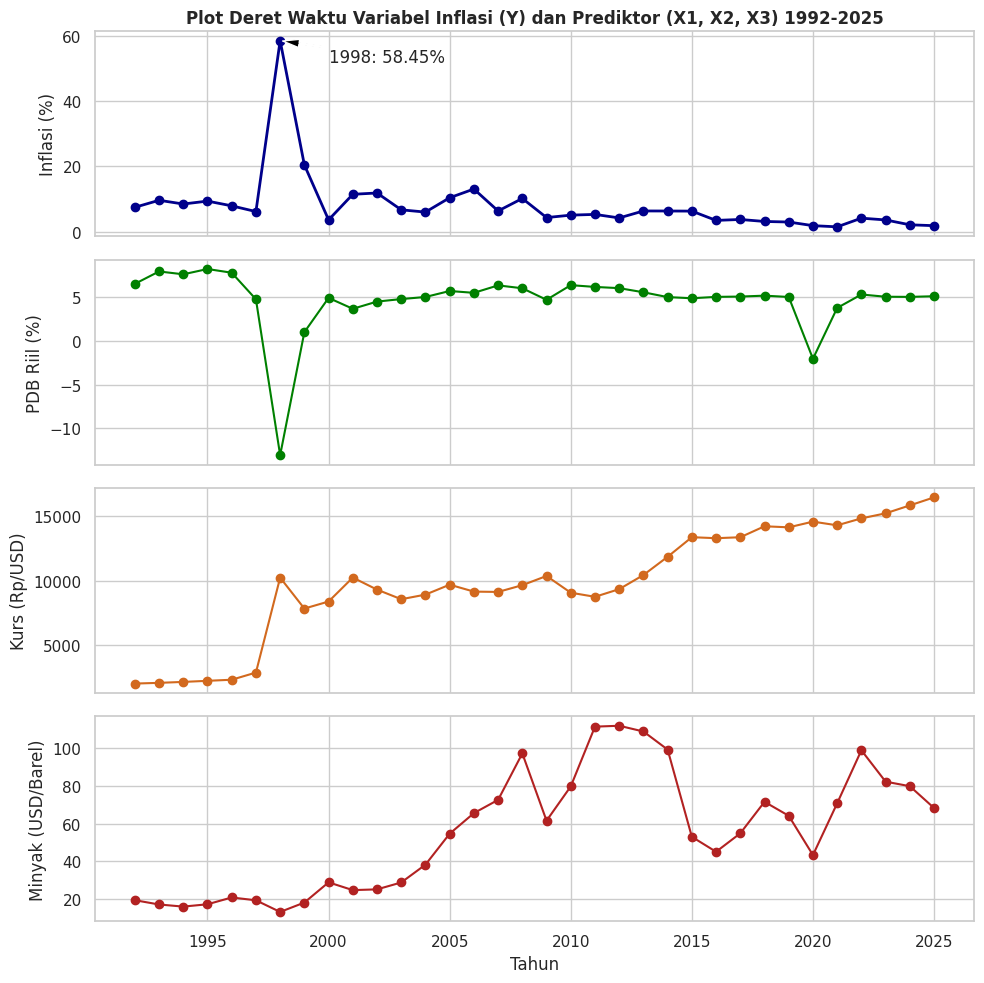

In [2]:
# Set style visualisasi
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)

# Plot Y: Inflasi
axes[0].plot(
    df["Tahun"],
    df["Inflasi % (Y)"],
    marker="o",
    color="darkblue",
    linewidth=2,
)
axes[0].set_ylabel("Inflasi (%)")
axes[0].set_title(
    "Plot Deret Waktu Variabel Inflasi (Y) dan Prediktor (X1, X2, X3) 1992-2025",
    fontsize=12,
    fontweight="bold",
)
axes[0].annotate(
    "1998: 58.45%",
    xy=(1998, 58.45),
    xytext=(2000, 52),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
)

# Plot X1: Pertumbuhan PDB Riil
axes[1].plot(
    df["Tahun"],
    df["Pertumbuhan PDB Riil % (X1)"],
    marker="o",
    color="green",
    linewidth=1.5,
)
axes[1].set_ylabel("PDB Riil (%)")

# Plot X2: Kurs Rp/USD
axes[2].plot(
    df["Tahun"], df["Kurs Rp/USD (X2)"], marker="o", color="chocolate", linewidth=1.5
)
axes[2].set_ylabel("Kurs (Rp/USD)")

# Plot X3: Harga Minyak Brent
axes[3].plot(
    df["Tahun"],
    df["Harga Minyak USD/ Barel (X3)"],
    marker="o",
    color="firebrick",
    linewidth=1.5,
)
axes[3].set_ylabel("Minyak (USD/Barel)")
axes[3].set_xlabel("Tahun")

plt.tight_layout()
plt.show()

In [3]:
# Definisi Variabel Independen (X) dan Dependen (Y)
X = df[
    [
        "Pertumbuhan PDB Riil % (X1)",
        "Kurs Rp/USD (X2)",
        "Harga Minyak USD/ Barel (X3)",
    ]
]
X_const = sm.add_constant(X)  # Menambahkan kolom Konstanta (β0)
y = df["Inflasi % (Y)"]

# Fitting Model OLS (Ordinary Least Squares)
model = sm.OLS(y, X_const).fit()

# Menampilkan Ringkasan Hasil Estimasi Regresi
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          Inflasi % (Y)   R-squared:                       0.794
Model:                            OLS   Adj. R-squared:                  0.774
Method:                 Least Squares   F-statistic:                     38.60
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           2.02e-10
Time:                        07:18:47   Log-Likelihood:                -98.180
No. Observations:                  34   AIC:                             204.4
Df Residuals:                      30   BIC:                             210.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

In [4]:
# 1. Menghitung Variance Inflation Factor (VIF) untuk Multikolinearitas
vif_data = pd.DataFrame()
vif_data["Variabel Prediktor"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_const.values, i + 1) for i in range(X.shape[1])
]

# 2. Menghitung Statistik Durbin-Watson (DW) untuk Autokorelasi
dw_stat = durbin_watson(model.resid)

print("=" * 55)
print("          UJI DIAGNOSTIK KESEHATAN MODEL")
print("=" * 55)
print("\n--- 1. NILAI VIF (UJI MULTIKOLINEARITAS) ---")
print(vif_data.to_string(index=False))
print("\nEvaluasi VIF: Semua VIF < 10 (Bebas Multikolinearitas)")

print("\n--- 2. STATISTIK DURBIN-WATSON (UJI AUTOKORELASI) ---")
print(f"Durbin-Watson Statistic = {dw_stat:.5f}")
print("Evaluasi DW: 1.65 < DW (1.882) < 2.35 (Gagal Tolak H0 / Bebas Autokorelasi)")
print("=" * 55)

          UJI DIAGNOSTIK KESEHATAN MODEL

--- 1. NILAI VIF (UJI MULTIKOLINEARITAS) ---
          Variabel Prediktor      VIF
 Pertumbuhan PDB Riil % (X1) 1.361326
            Kurs Rp/USD (X2) 1.867566
Harga Minyak USD/ Barel (X3) 1.823370

Evaluasi VIF: Semua VIF < 10 (Bebas Multikolinearitas)

--- 2. STATISTIK DURBIN-WATSON (UJI AUTOKORELASI) ---
Durbin-Watson Statistic = 1.88237
Evaluasi DW: 1.65 < DW (1.882) < 2.35 (Gagal Tolak H0 / Bebas Autokorelasi)


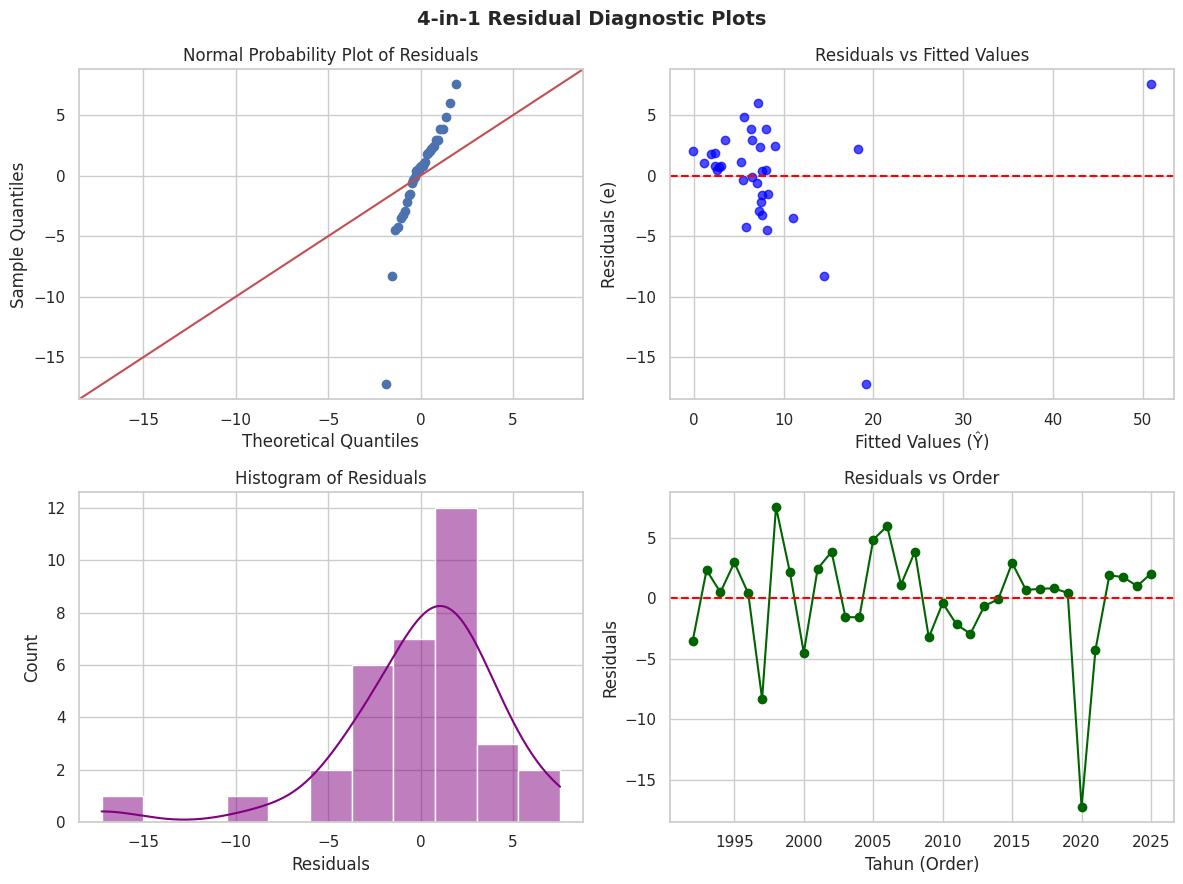

In [5]:
residuals = model.resid
fitted_values = model.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Normal Probability Plot of Residuals
sm.qqplot(residuals, line="45", ax=axes[0, 0])
axes[0, 0].set_title("Normal Probability Plot of Residuals")

# 2. Residuals vs Fitted Values (Homoskedastisitas)
axes[0, 1].scatter(fitted_values, residuals, color="blue", alpha=0.7)
axes[0, 1].axhline(y=0, color="red", linestyle="--")
axes[0, 1].set_xlabel("Fitted Values (Ŷ)")
axes[0, 1].set_ylabel("Residuals (e)")
axes[0, 1].set_title("Residuals vs Fitted Values")

# 3. Histogram of Residuals
sns.histplot(residuals, kde=True, ax=axes[1, 0], color="purple")
axes[1, 0].set_title("Histogram of Residuals")
axes[1, 0].set_xlabel("Residuals")

# 4. Residuals vs Order (Urutan Waktu)
axes[1, 1].plot(df["Tahun"], residuals, marker="o", color="darkgreen")
axes[1, 1].axhline(y=0, color="red", linestyle="--")
axes[1, 1].set_xlabel("Tahun (Order)")
axes[1, 1].set_ylabel("Residuals")
axes[1, 1].set_title("Residuals vs Order")

plt.suptitle("4-in-1 Residual Diagnostic Plots", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()